# 02 · Target construction and chronological split
**Task.** Predict PM2.5 one hour ahead from information available at hour *t*: **X(t) → PM2.5(t+1)** (µg/m³).
**Protocol.** The target is built from the raw series (never filled) and the last hour is removed. The earliest 80 % of the hours are the training period, the latest 20 % the
held-out test period. No shuffling. The test rows are moved into a `HeldOutTest` vault: only their date range is public, and every `unlock()` is logged.
**Code.** `src/data.py` (`make_target`, `chronological_split`, `HeldOutTest`).

In [1]:
import io, json, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
from src import config as C

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)

def table(stem, **kw):
    """results/tables/<stem>.csv (written by run_all.py)."""
    return pd.read_csv(C.TABLES / f"{stem}.csv", **kw)

def caption(stem):
    txt = (C.FIGURES / "figure_captions.md").read_text()
    m = re.search(rf"\*\*{re.escape(stem)}\*\* - (.*?)(?:\n\n|\Z)", txt, re.S)
    return m.group(1).strip() if m else ""

def fig(stem, width=1500):
    """Show results/figures/<stem>.png (down-scaled to keep the notebook small) with the caption computed from the data."""
    im = PILImage.open(C.FIGURES / f"{stem}.png")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue())); display(Markdown(f"*{caption(stem)}*"))

def log_grep(pattern, maxlen=420):
    """Print the lines of results/logs/run_all.log that match a regular expression."""
    for line in (C.LOGS / "run_all.log").read_text().splitlines():
        if re.search(pattern, line):
            print(line[:maxlen])

## 1. Target construction and split (live)

In [2]:
from src import data as D, features as F, models as M
raw = D.load_raw()
df, _ = D.build_datetime(raw)
df, _ = D.drop_identifier_columns(df)
df = D.make_target(df)                                     # target(t) = PM2.5(t+1); the last hour is removed; asserted inside
train, vault, info = D.chronological_split(df)             # earliest 80 % = train, latest 20 % = locked vault
del df                                                     # only the training rows stay in memory

print(f"train: {len(train):,} hours | test (locked): {vault.n_rows:,} hours")
display(train[["datetime", "PM2.5", "target"]].head(5))

train: 28,050 hours | test (locked): 7,013 hours


,datetime,PM2.5,target
0,2013-03-01 00:00:00,4.0,8.0
1,2013-03-01 01:00:00,8.0,7.0
2,2013-03-01 02:00:00,7.0,6.0
3,2013-03-01 03:00:00,6.0,3.0
4,2013-03-01 04:00:00,3.0,5.0


In [3]:
display(pd.Series(info, name="value").to_frame())
print(vault)                                                     # rows / date range only; nothing has been unlocked here
print("gap between the last training hour and the first test hour:", vault.start - train["datetime"].iloc[-1])
saved = json.loads((C.LOGS / "split_info.json").read_text())
assert saved == info, "the split differs from the one used by run_all.py"
print("identical to results/logs/split_info.json")

,value
n_total,35063
split_index,28050
n_train,28050
n_test,7013
train_start,2013-03-01 00:00:00
train_end,2016-05-12 17:00:00
test_start,2016-05-12 18:00:00
test_end,2017-02-28 22:00:00
test_fraction,0.2
shuffled,False


HeldOutTest(rows=7013, 2016-05-12 18:00:00 -> 2017-02-28 22:00:00, unlocked_in_this_session=0)
gap between the last training hour and the first test hour: 0 days 01:00:00
identical to results/logs/split_info.json


`make_target` asserts `target[:-1] == PM2.5[1:]` (the target is the next hour's reading) and that the target column is not the current PM2.5 column.
The split asserts that every training timestamp precedes every test timestamp and that the two periods are contiguous.

## 2. Figures

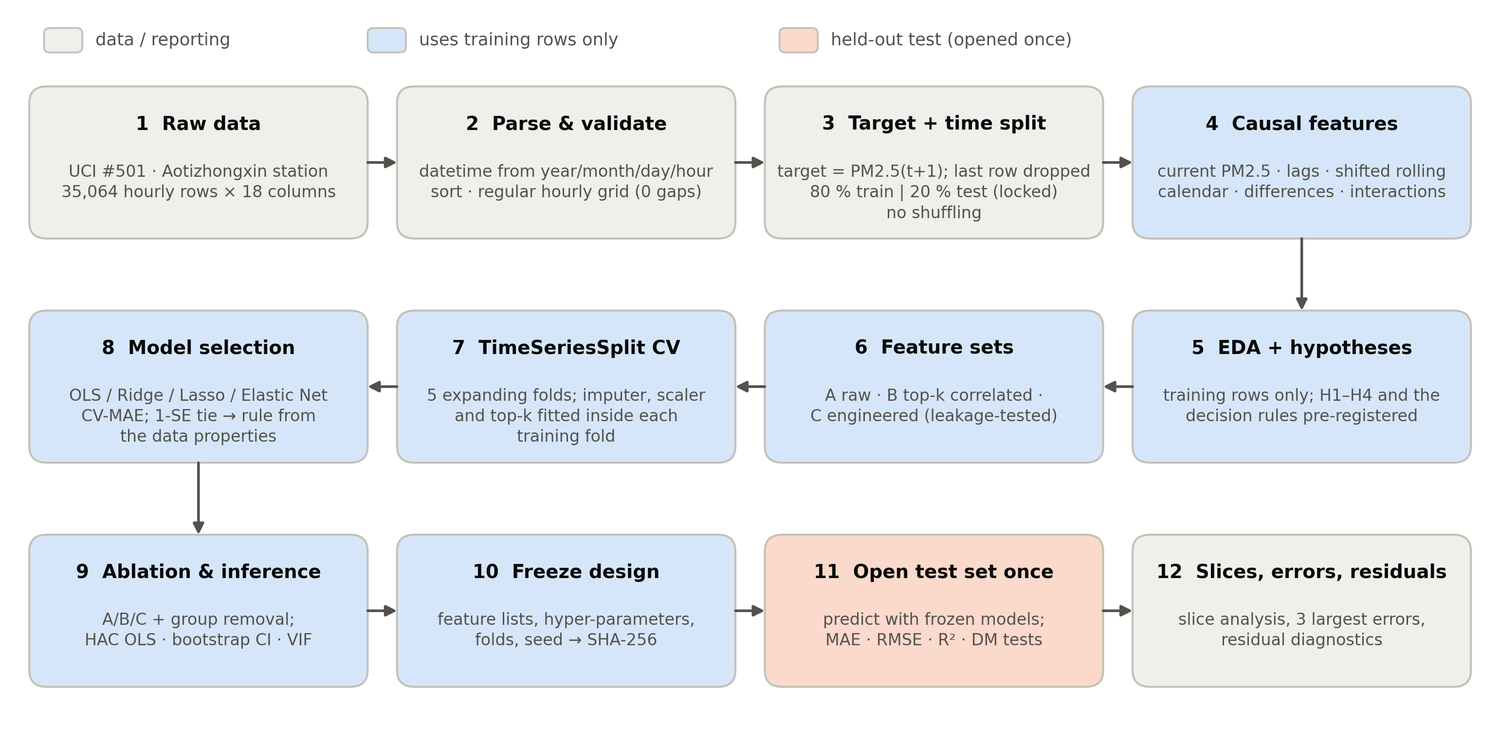

*Prediction pipeline for X(t) → PM2.5(t+1). Blue boxes use training rows only; the held-out test period (orange) is opened once per run, after the design has been frozen and fingerprinted.*

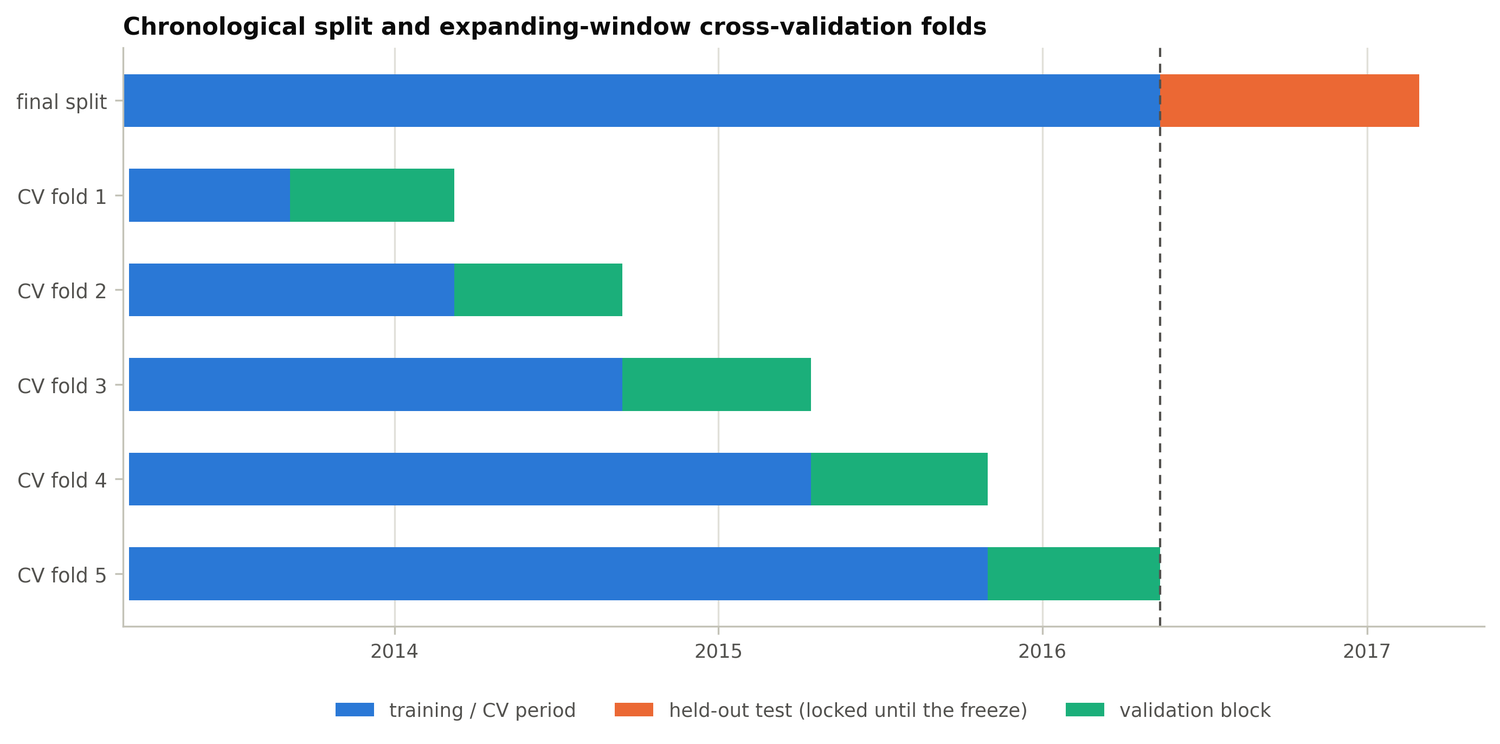

*Chronological split (28,050 training hours 2013-03-01 to 2016-05-12; 7,013 test hours 2016-05-12 to 2017-02-28, locked) and the 5 expanding-window folds on the 26,000 usable training rows: fold k is fitted on all rows up to its validation block, which lies strictly after it (fold 1: 4,335 rows, validation 2013-09-05 to 2014-03-09; fold 2: 8,668 rows, validation 2014-03-09 to 2014-09-14; fold 3: 13,001 rows, validation 2014-09-14 to 2015-04-15; fold 4: 17,334 rows, validation 2015-04-15 to 2015-10-31; fold 5: 21,667 rows, validation 2015-10-31 to 2016-05-12). All models, feature sets and ablations use these same folds.*

In [4]:
fig("figure_01_prediction_pipeline")
fig("figure_S08_split_and_cv_folds")

## 3. Access log of the held-out test period
The vault is opened only after the design (features, hyper-parameters, folds, seed) has been frozen and fingerprinted (SHA-256). One entry per execution of the pipeline that reached the test stage.

In [5]:
display(pd.DataFrame(json.loads((C.LOGS / "test_access_log.json").read_text())))

,time_utc,reason,design_sha256,n_test_rows
0,2026-10-04T18:24:18+00:00,single evaluation of the frozen design,d34f696ca0598698871d0d9315ec72c8dac274a3bf16c826f2fa75ed8a118677,7013
1,2026-10-04T18:59:34+00:00,single evaluation of the frozen design,869857f9b4fa8a4d4bc63925bc109961c92311d10081f75d21a91ca8b48b4c21,7013
2,2026-10-04T19:10:23+00:00,single evaluation of the frozen design,869857f9b4fa8a4d4bc63925bc109961c92311d10081f75d21a91ca8b48b4c21,7013
